<a href="https://colab.research.google.com/github/Hafsahshaikh/Generative-AI-Projects/blob/main/ANN_vs_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## MNIST Handwritten Digits Data

# ANN

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9262 - loss: 0.2545
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9658 - loss: 0.1139
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9762 - loss: 0.0788
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9822 - loss: 0.0586
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9855 - loss: 0.0459
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9767 - loss: 0.0787
Test accuracy: 97.67%
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


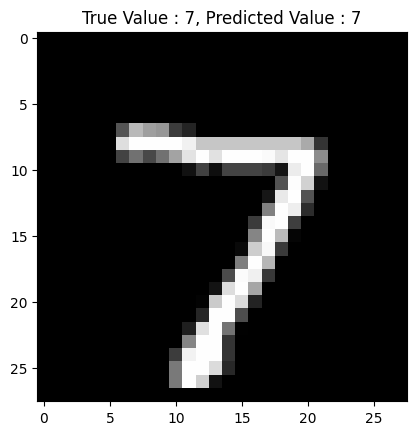

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train, x_test = x_train / 255.0, x_test / 255.0

model = models.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

# Dense layers expect a 1D input, so whenever the preceding layer produces multi-dimensional output,
# We must flatten it to 1D before passing it to a Dense layer

# If the input to a Dense layer is not already 1D, use Flatten to convert it to 1D

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit(x_train, y_train, epochs=5)

test_loss, test_accuracy = model.evaluate(x_test, y_test)
print(f'Test accuracy: {test_accuracy * 100:.2f}%')

predictions = model.predict(x_test)

plt.imshow(x_test[0], cmap='gray')
plt.title(f"True Value : {y_test[0]}, Predicted Value : {np.argmax(predictions[0])}")
plt.show()

In [2]:
model.layers

[<Flatten name=flatten, built=True>,
 <Dense name=dense, built=True>,
 <Dense name=dense_1, built=True>]

In [3]:
weights, biases = model.layers[1].get_weights()
print("Weights shape:", weights.shape)  # Shape of weight matrix
print("Biases shape:", biases.shape)    # Shape of bias vector
print("Weights")
print(weights)
print("Biases")
print(biases)

Weights shape: (784, 128)
Biases shape: (128,)
Weights
[[-0.0276318   0.04104995  0.07829288 ... -0.03610983 -0.07135984
  -0.03752939]
 [ 0.06014136 -0.02962881  0.03055264 ... -0.04041119  0.03569858
   0.0386942 ]
 [-0.0701322  -0.0433531   0.0789749  ... -0.03852504 -0.08106808
  -0.07889293]
 ...
 [ 0.00430051  0.02618096 -0.04327722 ...  0.02541878  0.00895885
   0.01894482]
 [-0.07092635 -0.02177233 -0.06911721 ...  0.02717944 -0.03143746
   0.08000413]
 [-0.05672333  0.04080795  0.05219639 ... -0.01405392 -0.0320097
   0.06378112]]
Biases
[ 7.82343745e-02 -1.06405534e-01 -5.07987477e-02  7.48255253e-02
  1.15677118e-01  1.11268103e-01  4.81532291e-02  1.60596922e-01
  6.81742951e-02 -8.10899436e-02  1.69500709e-06  4.63445187e-02
 -2.93843206e-02  3.68970484e-02  1.68663505e-02  7.18356222e-02
 -1.32112885e-02  4.65698577e-02 -8.62527341e-02 -3.43516469e-02
 -2.74875760e-02  1.31293520e-01  1.59558654e-02  1.04185686e-01
  3.08648404e-02  8.78695697e-02 -9.22713205e-02 -3.99421

In [4]:
weights, biases = model.layers[2].get_weights()
print("Weights shape:", weights.shape)  # Shape of weight matrix
print("Biases shape:", biases.shape)    # Shape of bias vector
print("Weights")
print(weights)
print("Biases")
print(biases)

Weights shape: (128, 10)
Biases shape: (10,)
Weights
[[-0.6921636  -0.14517146  0.0206176  ...  0.12985419  0.2521572
  -0.31301707]
 [ 0.3089169  -0.15148745  0.24775764 ...  0.23285133  0.00759627
   0.24540694]
 [ 0.05164971 -0.10363276 -0.15341775 ...  0.15136129 -0.27104315
  -0.2229801 ]
 ...
 [-0.29938194 -0.28654557 -0.11475367 ...  0.13794675  0.15983786
   0.2633762 ]
 [-0.17169975 -0.0402959  -0.10673545 ... -0.32471013 -0.44174215
   0.19023703]
 [ 0.17643218  0.144996    0.15706886 ... -0.35518393  0.17375648
  -0.14784907]]
Biases
[-0.10318092 -0.09834896  0.01398493 -0.14096357  0.07356352  0.06510773
  0.00739575 -0.04959296  0.1433143  -0.00090045]


# CNN

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 49s 25ms/step - accuracy: 0.9554 - loss: 0.1430
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 45s 24ms/step - accuracy: 0.9854 - loss: 0.0469
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 83s 24ms/step - accuracy: 0.9898 - loss: 0.0326
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 45s 24ms/step - accuracy: 0.9922 - loss: 0.0251
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 24ms/step - accuracy: 0.9941 - loss: 0.0185
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9905 - loss: 0.0360
Test accuracy: 99.05%
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step


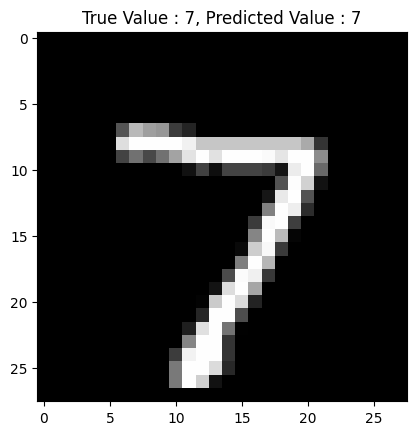

In [5]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt


(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# CNN expects 4D input: (batch, height, width, channels)
x_train = x_train.reshape(-1, 28, 28, 1) / 255.0
x_test = x_test.reshape(-1, 28, 28, 1) / 255.0


model = models.Sequential([
    # Convolution Layer 1: 32 filters of size 3x3
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),

    # Pooling Layer 1: reduces size to 14x14
    layers.MaxPooling2D((2, 2)),

    # Convolution Layer 2: 64 filters of size 3x3
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Pooling Layer 2: reduces size to 7x7
    layers.MaxPooling2D((2, 2)),

    # Flatten feature maps into 1D
    layers.Flatten(),

    # Dense hidden layer
    layers.Dense(64, activation='relu'),

    # Output layer (10 classes for digits 0–9)
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit(x_train, y_train, epochs=5)


test_loss, test_accuracy = model.evaluate(x_test, y_test)
print(f'Test accuracy: {test_accuracy * 100:.2f}%')

predictions = model.predict(x_test)

plt.imshow(x_test[0].squeeze(), cmap='gray')
plt.title(f"True Value : {y_test[0]}, Predicted Value : {np.argmax(predictions[0])}")
plt.show()


In [6]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 365,792 (1.40 MB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 243,862 (952.59 KB)

In [7]:
for i, layer in enumerate(model.layers):
    weights = layer.get_weights()
    if not weights:
        # layers like MaxPooling, Flatten, Activation (if separate) return []
        print(f"{i}: {layer.name} — no weights")
        continue

    w, b = weights  # conv and dense both return [w, b]
    print(f"{i}: {layer.name} ({layer.__class__.__name__})")
    print("  weights shape:", w.shape)
    print("  biases shape: ", b.shape)
    print()


0: conv2d (Conv2D)
  weights shape: (3, 3, 1, 32)
  biases shape:  (32,)

1: max_pooling2d — no weights
2: conv2d_1 (Conv2D)
  weights shape: (3, 3, 32, 64)
  biases shape:  (64,)

3: max_pooling2d_1 — no weights
4: flatten_1 — no weights
5: dense_2 (Dense)
  weights shape: (1600, 64)
  biases shape:  (64,)

6: dense_3 (Dense)
  weights shape: (64, 10)
  biases shape:  (10,)



In [8]:
# by index
w, b = model.layers[0].get_weights()
print("Layer 0:", model.layers[0].name)
print("weights shape:", w.shape)
print("biases shape:", b.shape)

# or by name
conv2 = model.get_layer(name='conv2d')  # replace name if different (or check model.summary())
w, b = conv2.get_weights()
print(w.shape, b.shape)


Layer 0: conv2d
weights shape: (3, 3, 1, 32)
biases shape: (32,)
(3, 3, 1, 32) (32,)


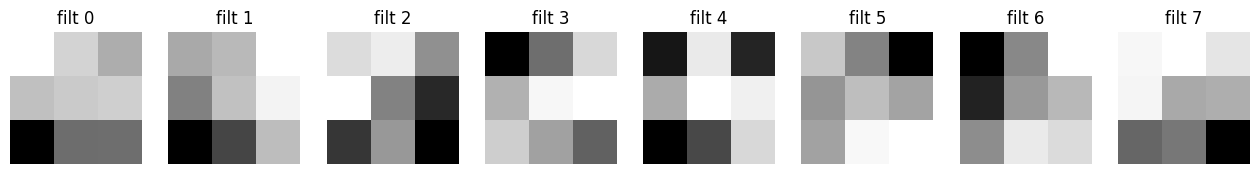

In [9]:
import matplotlib.pyplot as plt

kernel, bias = model.layers[0].get_weights()  # first Conv2D
# kernel.shape == (kernel_h, kernel_w, in_ch, out_ch)
kh, kw, in_ch, out_ch = kernel.shape

n = min(8, out_ch)  # show up to 8 filters
fig, axes = plt.subplots(1, n, figsize=(n*2, 2))
for i in range(n):
    # if single input channel, kernel[:, :, 0, i] is 2D image of the filter
    filt = kernel[:, :, 0, i]
    axes[i].imshow(filt, cmap='gray')
    axes[i].axis('off')
    axes[i].set_title(f"filt {i}")
plt.show()


In [10]:
w, b = model.layers[0].get_weights()
print("kernel values for filter 0:\n", w[:, :, :, 0])
print("bias for filter 0:", b[0])


kernel values for filter 0:
 [[[ 0.16667195]
  [ 0.08082008]
  [ 0.00248762]]

 [[ 0.04113032]
  [ 0.06037438]
  [ 0.07001617]]

 [[-0.34005177]
  [-0.12261193]
  [-0.12189466]]]
bias for filter 0: -0.017564133
